<H3>PRI 2024/25: second
    project delivery</H3>

**GROUP 9**
- Diogo Dinis, 99066
- Afonso Lança, 103838
- Luís Calado, 103883

<H2>Main facilities</H2>

In [ ]:
!pip install pytrec_eval
!pip install ir_datasets

In [2]:
# --- Import Libraries ---

import ir_datasets
import pytrec_eval
import re
import nltk
from time import time
from nltk.corpus import stopwords
from nltk.corpus import wordnet as wn
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from collections import Counter, defaultdict, namedtuple
import math
import seaborn as sns
import pandas as pd

import numpy as np
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from scipy.spatial.distance import jaccard, cityblock
from sklearn.cluster import *
from sklearn.metrics import silhouette_score, silhouette_samples
import random

import matplotlib.pyplot as plt

# Download necessary NLTK resources
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /home/afonso/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/afonso/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/afonso/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [3]:
# --- Load Dataset ---
dataset = ir_datasets.load("cord19/trec-covid/round1")

queries = [query for query in dataset.queries_iter()]

qrels = {}

for qrel in dataset.qrels_iter():
    qrels.setdefault(qrel.query_id, {})[qrel.doc_id] = qrel.relevance

docs = [doc for doc in dataset.docs_iter()]

In [4]:
# --- Load Dataset Function ---
def load_ir_dataset(dataset_name):
    # --- Load Dataset ---
    dataset = ir_datasets.load(dataset_name)

    # Get queries
    queries = [query for query in dataset.queries_iter()]

    # Get relevance judgments
    qrels = {}
    for qrel in dataset.qrels_iter():
        qrels.setdefault(qrel.query_id, {})[qrel.doc_id] = qrel.relevance

    # Get documents
    docs = [doc for doc in dataset.docs_iter()]

    return dataset, queries, qrels, docs

In [5]:
# --- Preprocessing Functions --

stopwords_set = set(stopwords.words("english"))
non_alpha_numeric = re.compile(r'[^a-z0-9\s]')
def preprocess(text, stopwords=stopwords_set):
    """Normalize and preprocess a text string."""
    text = text.lower()
    text = non_alpha_numeric.sub(" ", text)
    words = word_tokenize(text)
    lemmatizer = WordNetLemmatizer()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stopwords]
    return words  # Return list of tokens

def preprocess_corpus(docs, stop_words=stopwords_set, preprocess_text=True):
    preprocessed_docs = {}
    for doc in docs:
        docid = doc.doc_id
        # Combine title and abstract.
        doc_text = f"{doc.title} {doc.abstract}"
        if preprocess_text:
            tokens = preprocess(doc_text, stop_words)
        else:
            tokens = doc_text.split()
        preprocessed_docs[docid] = tokens
    return preprocessed_docs

def expand_query(query, max_synonyms_per_term=2):
    # Tokenize and lemmatize the query.
    lemmatizer = WordNetLemmatizer()
    tokens = word_tokenize(query)
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Initialize expanded tokens with the lemmatized tokens.
    expanded_tokens = set(lemmatized_tokens)

    # For each lemmatized token, add up to max_synonyms_per_term synonyms.
    for token in lemmatized_tokens:
        synsets = wn.synsets(token)
        synonyms = []
        for syn in synsets:
            for lemma in syn.lemmas():
                syn_name = lemma.name().replace("_", " ")
                # Only add if the synonym is different and not already included.
                if syn_name.lower() != token.lower() and syn_name not in expanded_tokens:
                    synonyms.append(syn_name)
        for syn in synonyms[:max_synonyms_per_term]:
            expanded_tokens.add(syn)

    return " ".join(expanded_tokens)

<H2> Useful functions from 1st delivery </H2>

In [6]:
# --- Indexing Functions ---

def build_inverted_index_from_tokens(preprocessed_docs):
    postings = defaultdict(dict)
    doc_len = defaultdict(int)
    for docid, tokens in preprocessed_docs.items():
        doc_vector = Counter(tokens)
        for term, tf in doc_vector.items():
            postings[term][docid] = tf
            doc_len[docid] += tf
    return postings, doc_len

def indexing(docs, stopwords_lang="english", preprocess_text=True):
    stop_words = set(stopwords.words(stopwords_lang))
    TfIndex = namedtuple("tf_index", "postings doc_len avg_doc_len")

    preprocessed_docs = preprocess_corpus(docs, stop_words, preprocess_text)

    postings, doc_len = build_inverted_index_from_tokens(preprocessed_docs)

    # Compute overall index statistics.
    N = len(preprocessed_docs)
    total_length = sum(doc_len.values())
    avg_doc_len = total_length / N if N > 0 else 0

    return TfIndex(postings, doc_len, avg_doc_len)

In [7]:
# --- Ranking Functions ---

def tf(t, d, I, doc_len, weighting_tf="n", **kwargs):
    f_td = I.postings[t].get(d, 0)
    if f_td == 0:
        return 0
    if weighting_tf == "n":
        return f_td / doc_len
    elif weighting_tf == "l":
        return 1 + math.log(f_td)

def idf(t, I, N, weighting_idf="t", **kwargs):
    df = len(I.postings[t])
    if weighting_idf == "n":
        return 1
    elif weighting_idf == "t":
        return math.log(N / df)
    elif weighting_idf == "p":
        return max(0, math.log((N - df) / df))

def ranking(q, p, I, scoring_function, **kwargs):
    stop_words = set(stopwords.words("english"))
    query_terms = preprocess(q, stop_words)

    # Only consider docs that contain at least one query term.
    candidate_docs = set()
    for qt in query_terms:
        if qt in I.postings:
            candidate_docs.update(I.postings[qt].keys())

    scores = []
    N = len(I.doc_len)
    for d in candidate_docs:
        score = 0
        for qt in query_terms:
            if qt in I.postings and d in I.postings[qt]:
                score += scoring_function(qt, d, I, N, I.doc_len[d], avg_doc_len=I.avg_doc_len, **kwargs)
        scores.append((d, score))
    ranked_results = sorted(scores, key=lambda x: x[1], reverse=True)[:p]
    return ranked_results

In [8]:
# --- Ranked IR Models ---

def tf_idf(t, d, I, N, doc_len, weighting_tf="l", weighting_idf="t", **kwargs):
    return tf(t, d, I, doc_len, weighting_tf=weighting_tf) * idf(t, I, N, weighting_idf=weighting_idf)

def bm25(t, d, I, N, doc_len, k1=1.1, b=0.4, **kwargs):
    avg_doc_len = kwargs.get('avg_doc_len', 1)
    idf_value = idf(t, I, N)
    f_td = I.postings[t].get(d, 0)
    if f_td == 0:
        return 0
    numerator = idf_value * f_td * (k1 + 1)
    denominator = f_td + k1 * (1 - b + b * (doc_len / avg_doc_len))
    return numerator / denominator

def reciprocal_rank_fusion(query, num_retrieval, I, scoring_functions, y=50, **kwargs):
    scores = {}
    for scoring_func_name, scoring_func in scoring_functions.items():
        ranked_results = ranking(query.title, num_retrieval, I, scoring_func, **kwargs)
        for i, (docid, _) in enumerate(ranked_results):
            if docid not in scores:
                scores[docid] = 0
            scores[docid] += 1 / (i + y)

    ranked_rrf = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:num_retrieval]
    return ranked_rrf

In [9]:
index = indexing(docs)

<h3>Part I: clustering</h3>

*A) Clustering*

In [10]:
# --- Clustering Function ---

def clustering(items, n_clusters, distance_metric, algorithm, min_df, max_df, is_query):
    vectorizer = TfidfVectorizer(min_df=min_df, max_df=max_df)

    # Extract IDs and documents based on item type
    if is_query:
        item_ids = [item.query_id for item in items]
        documents = [' '.join(preprocess(item.title)) for item in items]
    else:
        item_ids = [item.doc_id for item in items]
        documents = [' '.join(preprocess(item.title + " " + item.abstract)) for item in items]

    # Build TF‑IDF matrix
    X = vectorizer.fit_transform(documents)

    # Compute distance matrix
    if distance_metric == 'euclidean':
        distance_matrix = euclidean_distances(X)
    elif distance_metric == 'cosine':
        distance_matrix = 1 - cosine_similarity(X)
    else:
        raise ValueError(f"Unsupported distance metric: {distance_metric}")

    # Select and run the clustering algorithm
    if algorithm == 'kmeans':
        clustering_model = KMeans(n_clusters=n_clusters, random_state=42)
        clustering_model.fit(X)
        labels = clustering_model.labels_
    elif algorithm == 'agglomerative':
        clustering_model = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
        labels = clustering_model.fit_predict(X.toarray())
    elif algorithm == 'dbscan':
        clustering_model = DBSCAN(metric=distance_metric)
        labels = clustering_model.fit_predict(distance_matrix)
    elif algorithm == 'spectral':
        affinity = 'precomputed' if distance_metric != 'euclidean' else 'rbf'
        clustering_model = SpectralClustering(n_clusters=n_clusters, affinity=affinity, random_state=42)
        labels = clustering_model.fit_predict(distance_matrix if distance_metric != 'euclidean' else X)
    elif algorithm == 'birch':
        clustering_model = Birch(n_clusters=n_clusters)
        clustering_model.fit(X)
        labels = clustering_model.labels_
    else:
        raise ValueError(f"Unsupported clustering algorithm: {algorithm}")

    # Build clusters dictionary
    clusters = defaultdict(list)
    for item_id, label in zip(item_ids, labels):
        clusters[label].append(item_id)

    # Calculate centroids
    centroids = {}
    X_array = X.toarray()
    for label, cluster_item_ids in clusters.items():
        indices = [i for i, id_val in enumerate(item_ids) if id_val in cluster_item_ids]
        cluster_vectors = X_array[indices]
        centroid = np.mean(cluster_vectors, axis=0)
        centroids[label] = centroid

    return {
        'clusters': clusters,
        'centroids': centroids,
        'X': X_array,
        'item_ids': item_ids,
        'labels': labels,
        'distance_matrix': distance_matrix
    }

In [11]:
# --- Dataset Clustering Demo ---

# Load Dataset
dataset, queries, qrels, docs = load_ir_dataset("cord19/trec-covid/round1")
docs_data = docs[:10]

clustering_result = clustering(docs_data, n_clusters=3, distance_metric='cosine',
                              algorithm='kmeans', min_df=1, max_df=1.0, is_query=False)

# Print clustering results
print("Clusters:")
for label, doc_ids in clustering_result['clusters'].items():
    print(f"Cluster {label}: {doc_ids}")

Clusters:
Cluster 1: ['xqhn0vbp', 'le0ogx1s', 'qj4dh6rg', '1wswi7us', 'yy96yeu9']
Cluster 2: ['gi6uaa83', '5o38ihe0']
Cluster 0: ['fy4w7xz8', '0qaoam29', '1ul8owic']


*B) Interpretation*

In [12]:
def interpret(cluster_items, items, X, item_ids, distance_matrix, is_query=False):
    # Filter to only the items in this cluster
    cluster_indices = [i for i, id_val in enumerate(item_ids) if id_val in cluster_items]
    cluster_vectors = X[cluster_indices]

    # Get the centroid
    centroid = np.mean(cluster_vectors, axis=0)

    # Compute medoid: document closest to centroid
    distances_to_centroid = np.linalg.norm(cluster_vectors - centroid, axis=1)
    medoid_index = np.argmin(distances_to_centroid)
    medoid_id = cluster_items[medoid_index]

    # Compute median: document with median sum of distances to others
    # Extract the distance submatrix for just this cluster
    cluster_distance_matrix = distance_matrix[np.ix_(cluster_indices, cluster_indices)]
    distance_sums = np.sum(cluster_distance_matrix, axis=1)
    median_value = np.median(distance_sums)
    median_index = np.argmin(np.abs(distance_sums - median_value))
    median_id = cluster_items[median_index]

    # Build a dictionary of items in the cluster using the appropriate ID attribute
    if is_query:
        cluster_item_dict = {item.query_id: item for item in items if item.query_id in cluster_items}
    else:
        cluster_item_dict = {item.doc_id: item for item in items if item.doc_id in cluster_items}

    # Process tokens for all items in the cluster
    processed_items = {}
    for item_id, item in cluster_item_dict.items():
        if is_query:
            title_tokens = preprocess(item.title)
            abstract_tokens = []
        else:
            title_tokens = preprocess(item.title)
            abstract_tokens = preprocess(item.abstract)
        processed_items[item_id] = (title_tokens, abstract_tokens)

    results = {}

    # Use the medoid and median IDs to create interpretations
    results['interpret_medoid'] = ' '.join(processed_items[medoid_id][0])
    results['interpret_median'] = ' '.join(processed_items[median_id][0])
    results['medoid_id'] = medoid_id
    results['median_id'] = median_id

    # Calculate common words from both the title and abstract tokens
    all_words = []
    for tokens, extra_tokens in processed_items.values():
        all_words.extend(tokens + extra_tokens)
    word_counts = Counter(all_words)
    common_words = word_counts.most_common(10)
    results['interpret_common_words'] = ' '.join([word for word, count in common_words])

    return results

In [13]:
# --- Cluster Interpretation Demo ---

# Define cluster to be interpreted
cluster_label = 0
cluster_items = clustering_result['clusters'][cluster_label]

interpretation = interpret(
    cluster_items=cluster_items,
    items=docs_data,
    X=clustering_result['X'],
    item_ids=clustering_result['item_ids'],
    distance_matrix=clustering_result['distance_matrix'],
    is_query=False
)

print(f"Interpretation for Cluster {cluster_label}:")
print(f"Medoid document ID: {interpretation['medoid_id']}")
print(f"Medoid interpretation: {interpretation['interpret_medoid']}")
print(f"Median document ID: {interpretation['median_id']}")
print(f"Median interpretation: {interpretation['interpret_median']}")
print(f"Common words in cluster: {interpretation['interpret_common_words']}")


Interpretation for Cluster 0:
Medoid document ID: fy4w7xz8
Medoid interpretation: association hla class severe acute respiratory syndrome coronavirus infection
Median document ID: 1ul8owic
Median interpretation: air pollution case fatality sars people republic china ecologic study
Common words in cluster: sars hla case patient region epidemic air pollution group probable


*C) Evaluation*

In [14]:
# --- Clustering Evaluation Function ---

def evaluate(items, n_clusters=5, distance_metric='euclidean', algorithm='kmeans', min_df=1, max_df=1.0, is_query=False):
    # Run clustering.
    clustering_result = clustering(items, n_clusters, distance_metric, algorithm, min_df, max_df, is_query)
    X_array = clustering_result['X']
    labels = clustering_result['labels']

    # Compute Silhouette Scores per sample and group by cluster.
    sample_silhouette = silhouette_samples(X_array, labels, metric='cosine')
    silhouette_dict = defaultdict(list)
    for lab, score in zip(labels, sample_silhouette):
        silhouette_dict[lab].append(score)

    return {
        'clustering_solution': clustering_result,
        'silhouette': dict(silhouette_dict)
    }

In [15]:
# --- Clustering Evaluation Demo ---

evaluation_result = evaluate(
    items=docs_data,
    n_clusters=5,
    distance_metric='cosine',
    algorithm='kmeans',
    min_df=1,
    max_df=1.0,
    is_query=False
)

# Extract results
clustering_solution = evaluation_result['clustering_solution']
silhouette_scores = evaluation_result['silhouette']

# Print silhouette scores per cluster
print("\nSilhouette Scores by Cluster:")
for cluster_id, scores in silhouette_scores.items():
    avg_score = sum(scores) / len(scores)
    print(f"Cluster {cluster_id}: {avg_score:.4f} (min: {min(scores):.4f}, max: {max(scores):.4f})")

# Calculate and print overall silhouette score
all_silhouette_values = []
for cluster_values in silhouette_scores.values():
    all_silhouette_values.extend(cluster_values)
overall_silhouette = sum(all_silhouette_values) / len(all_silhouette_values)

print(f"\nOverall Silhouette Score: {overall_silhouette:.4f}")



Silhouette Scores by Cluster:
Cluster 4: 0.0000 (min: 0.0000, max: 0.0000)
Cluster 2: 0.0135 (min: -0.0119, max: 0.0389)
Cluster 1: 0.0078 (min: -0.0220, max: 0.0306)
Cluster 0: 0.0972 (min: 0.0571, max: 0.1226)
Cluster 3: 0.0000 (min: 0.0000, max: 0.0000)

Overall Silhouette Score: 0.0342


<h3>Part II: Graph ranking</h3>

*A) Build Graph*

In [16]:
# --- Similarity Metrics Functions --

similarity_metrics = {
    "jaccard": jaccard,
    "cosine": cosine_similarity,
    "euclidean": euclidean_distances,
    "manhattan": cityblock
}

def cosine(doc_vectors):
    return cosine_similarity(doc_vectors)

def euclidean(sim_matrix, doc_vectors):
    distances = euclidean_distances(doc_vectors)
    # Convert distances to similarity
    sim_matrix = 1 / (1 + distances)
    return sim_matrix

def jaccard(sim_matrix, doc_vectors, num_docs):
    # binary representation
    binary_vectors = (doc_vectors > 0).astype(int)
    for i in range(num_docs):
        for j in range(i + 1, num_docs):
            sim_matrix[i, j] = 1 - jaccard(binary_vectors[i].toarray()[0], binary_vectors[j].toarray()[0])
            sim_matrix[j, i] = sim_matrix[i, j]  # Symmetric

    return sim_matrix

def manhattan(sim_matrix, doc_vectors):
    distances = cityblock(doc_vectors.toarray())
    # Convert distances to similarity
    sim_matrix = 1 / (1 + distances)
    return sim_matrix

def similarity_matrix(sim, doc_vectors):
    num_docs = doc_vectors.shape[0]
    sim_matrix = np.zeros((num_docs, num_docs))

    if sim == 'cosine':
        return cosine(doc_vectors)

    elif sim == 'euclidean':
        return euclidean(sim_matrix, doc_vectors)

    elif sim == 'jaccard':
        return jaccard(sim_matrix, doc_vectors, num_docs)

    elif sim == 'cityblock':
        return manhattan(sim_matrix, doc_vectors)

In [17]:
# --- Graph Construction Functions ---

def first_stage_retrieval(I, documents, query):

  preprocessed_docs = preprocess_corpus(documents, preprocess_text=True)

  top_docs = {}
  ranked_bm25 = ranking(query.title, 1000, I, bm25)

  for doc_id, score in ranked_bm25:
      top_docs[doc_id] = (preprocessed_docs[doc_id], score)

  return top_docs


def build_graph(documents, sim="cosine", theta=0.1):
    docs_list = [' '.join(tokens) for tokens, _ in documents.values()]
    doc_ids = list(documents.keys())

    # Convert documents to TF-IDF vectors
    vectorizer = TfidfVectorizer()
    doc_vectors = vectorizer.fit_transform(docs_list)

    # Compute cosine similarity matrix
    sim_matrix = similarity_matrix(sim, doc_vectors)

    # Create graph
    G = nx.Graph()

    # Add nodes
    for doc_id in doc_ids:
        G.add_node(doc_id)

    # Add edges
    num_docs = len(doc_ids)
    for i in range(num_docs):
        for j in range(i + 1, num_docs):
            if sim_matrix[i, j] > theta:
                G.add_edge(doc_ids[i], doc_ids[j], weight=sim_matrix[i, j])

    return G

In [18]:
# --- Build Graph Demo ---
top_docs = first_stage_retrieval(index, docs, queries[0])
G = build_graph(top_docs, "cosine", 0.1)
print(G)

Graph with 1000 nodes and 23914 edges


In [19]:
def build_query_graphs(I, D, queries, sim="cosine", theta=0.1, num_graphs=30):
    queries_graphs = {}
    # Limit the number of queries to process based on num_graphs
    for i, query in enumerate(queries):
        top_docs = first_stage_retrieval(I, D, query)
        queries_graphs[query.query_id] = (build_graph(top_docs, sim, theta), top_docs)
        if i + 1 == num_graphs: break

    return queries_graphs

In [20]:
G = build_query_graphs(index, docs, queries, num_graphs=1)
query_id = queries[0].query_id
print(G[query_id][0])

Graph with 1000 nodes and 23914 edges


*B) Undirected Page Rank*

In [21]:
# --- Page Rank Functions --

def undirected_page_rank(G, top_docs, p=1000, sim="cosine", theta=0.1, max_iter=50, damping=0.85):
    # p = 1 - damping = 0.15 (default)
    nodes = list(G.nodes)
    N = len(nodes)
    PR = {node: 1 / N for node in nodes}

    for _ in range(max_iter):
        new_PR = {}
        for node in nodes:
            links = list(G.neighbors(node))
            if not links:
                # p / N
                new_PR[node] = (1 - damping) / N
            else:
                # p / N +  (1 - p) * sum (PR(dj) / Links(dj))
                new_PR[node] = (1 - damping) / N + damping * sum(
                    PR[neighbor] / len(list(G.neighbors(neighbor)))
                    for neighbor in links
                )
        PR = new_PR

    ranked_docs = sorted(PR.items(), key=lambda x: x[1], reverse=True)
    return ranked_docs[:p]

def weighted_page_rank(G, top_docs, p=1000, sim="cosine", theta=0.1, max_iter=50, damping=0.85, alpha=0.5):
    doc_scores = {doc_id: score for doc_id, (_, score) in top_docs.items()}

    nodes = list(G.nodes)
    N = len(nodes)
    total_doc_score = sum(doc_scores.values())

    PR = {node: 1 / N for node in nodes}

    outgoing_weights = {
        node: sum(G[node][nbr]['weight'] for nbr in G.neighbors(node))
        for node in nodes
    }

    for _ in range(max_iter):
        new_PR = {}
        for node in nodes:
            links = list(G.neighbors(node))
            prior_contrib = (1 - damping) * (doc_scores.get(node, 0) / total_doc_score)

            if not links:
                new_PR[node] = prior_contrib

            else:
                link_contrib = damping * sum(
                    PR[neighbor] * G[neighbor][node]['weight'] / outgoing_weights[neighbor]
                    for neighbor in links
                )

                new_PR[node] = prior_contrib + link_contrib

        PR = new_PR

    final_scores = {
        doc_id: alpha * PR[doc_id] + (1 - alpha) * doc_scores.get(doc_id, 0)
        for doc_id in nodes
    }

    ranked_docs = sorted(final_scores.items(), key=lambda x: x[1], reverse=True)
    return ranked_docs[:p]

In [22]:
# --- PageRank Demo ---
q = queries[0].query_id
print("--- Undirected PageRank ---")
print(undirected_page_rank(G[q][0], G[q][1])[:10])
print("--- Weighted PageRank ---")
print(weighted_page_rank(G[q][0], G[q][1])[:10])

--- Undirected PageRank ---
[('9sdehh8v', 0.00467836638923749), ('52kqp9yw', 0.004239712949625337), ('a21ub1e9', 0.003783332754145233), ('k560qnyi', 0.0036955055044741295), ('89fol3pq', 0.0035447626467277975), ('msohf5oa', 0.003391248352936227), ('t3t20wji', 0.003362561970936126), ('k0f9fser', 0.003355412849279033), ('d2knbzhl', 0.003309780375108632), ('sn7rswab', 0.0032527029031832913)]
--- Weighted PageRank ---
[('mv3crcsh', 4.51074739328856), ('llv3cvdr', 4.381313885094377), ('8l411r1w', 4.2579163496470915), ('es7q6c90', 4.170436519594908), ('zy8qjaai', 4.128840475889815), ('ne5r4d4b', 4.013281350357613), ('dnxhtbxn', 3.998652284423925), ('p0kv1pht', 3.982076223567354), ('ec8lpgl3', 3.972184287192102), ('0194oljo', 3.957807383253377)]


*C) Evaluation*

In [23]:
def evaluation(G, Q, R, metrics, num_retrieval, ranking_method="weighted", **kwargs):
    rankings = {}

    if ranking_method == "weighted":
        rank_function = weighted_page_rank
    elif ranking_method == "undirected":
        rank_function = undirected_page_rank

    for query in Q:
        ranked_docs = rank_function(G[query.query_id][0], G[query.query_id][1], p=num_retrieval, **kwargs)
        rankings[query.query_id] = {doc_id: float(score) for doc_id, score in ranked_docs}

    evaluator = pytrec_eval.RelevanceEvaluator(R, metrics)
    per_query_results = evaluator.evaluate(rankings)

    aggregated_metrics = {
        metric: sum(run_result[metric] for run_result in per_query_results.values()) / len(per_query_results)
        for metric in metrics
    }

    return aggregated_metrics, per_query_results

In [24]:
# --- PageRank Evaluation Demo ---

metrics = {'map', 'ndcg', 'P_10', 'ndcg_cut_10'}
num_graphs = 10     # For the report this was set to 30
sub_queries = queries[:num_graphs]
G = build_query_graphs(index, docs, sub_queries, num_graphs=num_graphs)

print("Undirected PageRank Evaluation:")
elapsed_time = time()
aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, 1000, ranking_method="undirected")
elapsed_time = time() - elapsed_time
print(f"Took {elapsed_time:.4f} seconds to evaluate the IR system, {elapsed_time / len(sub_queries):.4f} seconds per query")

print("Aggregated Evaluation Metrics:")
for metric, value in aggregated_metrics.items():
    print(f"{metric}: {value:.4f}")


print("Weigthed PageRank Evaluation:")
elapsed_time = time()
aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, 1000, ranking_method="weighted")
elapsed_time = time() - elapsed_time
print(f"Took {elapsed_time:.4f} seconds to evaluate the IR system, {elapsed_time / len(sub_queries):.4f} seconds per query")

print("Aggregated Evaluation Metrics:")
for metric, value in aggregated_metrics.items():
    print(f"{metric}: {value:.4f}")

Undirected PageRank Evaluation:
Took 26.5883 seconds to evaluate the IR system, 2.6588 seconds per query
Aggregated Evaluation Metrics:
P_10: 0.2000
ndcg_cut_10: 0.1507
ndcg: 0.2865
map: 0.0723
Weigthed PageRank Evaluation:
Took 23.7201 seconds to evaluate the IR system, 2.3720 seconds per query
Aggregated Evaluation Metrics:
P_10: 0.4300
ndcg_cut_10: 0.3798
ndcg: 0.3706
map: 0.1476


<H2>Question materials (optional)</H2>

<H3>Part I: clustering</H3>

**(1)** What is the (hypothesized) number of topic clusters? And document clusters in the Dtrain collection?:

In [25]:
# --- Clustering over range of k clusters Function ---

def find_best_clustering(data, min_k=2, max_k=20, distance_metric='euclidean', algorithm='kmeans', min_df=1, max_df=1.0, is_query=False):
    best_k = 0
    best_score = -1
    best_clustering = None
    k_silhouette = []

    # Loop over k values in the specified range.
    for k in range(min_k, max_k):
        clustering_result = clustering(
            data, n_clusters=k, distance_metric=distance_metric, algorithm=algorithm,
            min_df=min_df, max_df=max_df, is_query=is_query
        )
        score = silhouette_score(clustering_result['X'], clustering_result['labels'], metric='cosine')
        if score >= best_score:
            best_k = k
            best_score = score
            best_clustering = clustering_result

        k_silhouette.append((k, score))

    return {
        'best_k': best_k,
        'best_score': best_score,
        'best_clustering': best_clustering,
        'k_silhouette': k_silhouette
    }

Best k: 20, Best Silhouette Score: 0.0197828693039809


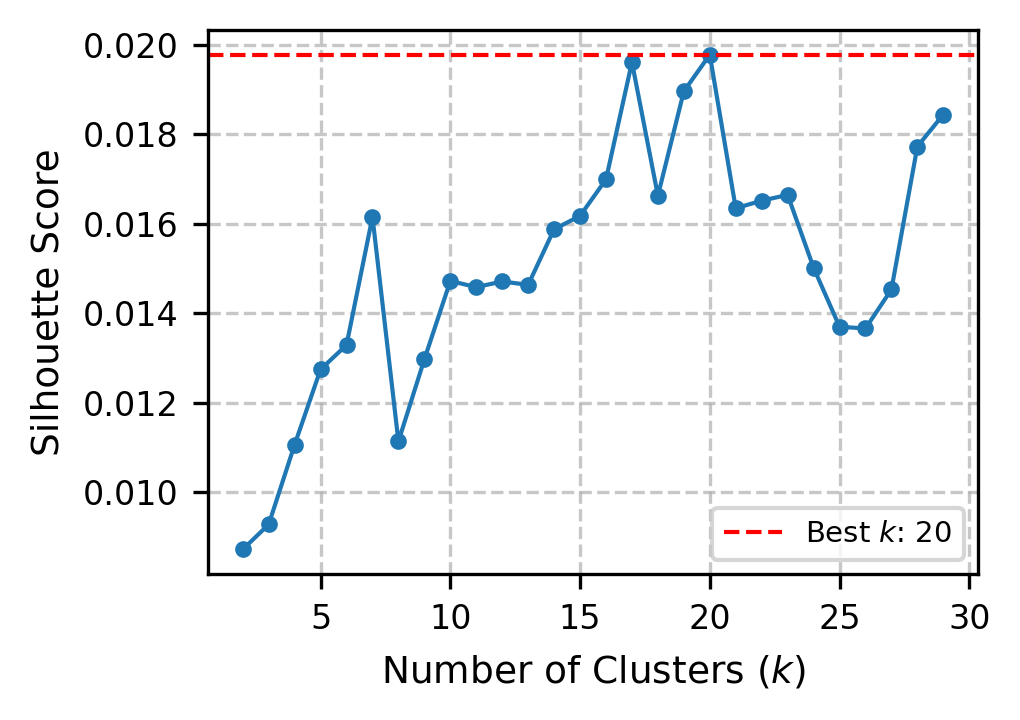

In [26]:
# --- Q1 | CORPUS ---

# Load Dataset
dataset, queries, qrels, docs = load_ir_dataset("cord19/trec-covid/round1")

# Select Subset
random.seed(53)
docs_data = random.sample(docs, 1000)

# Use the function to find best clustering
results = find_best_clustering(docs_data, min_k=2, max_k=30, distance_metric='cosine', algorithm='kmeans', is_query=False)

# Extract results
docs_best_k = results['best_k']
best_score = results['best_score']
best_clustering = results['best_clustering']
k_silhouette = results['k_silhouette']

# Present Results
print(f"Best k: {docs_best_k}, Best Silhouette Score: {best_score}")
plt.figure(figsize=(3.5, 2.5), dpi=300)
plt.plot([k for k, score in k_silhouette], [score for k, score in k_silhouette],
         marker='o', markersize=3, linewidth=1)
plt.xlabel('Number of Clusters ($k$)', fontsize=9)
plt.ylabel('Silhouette Score', fontsize=9)
plt.axhline(y=best_score, color='r', linestyle='--', linewidth=1,
            label=f'Best $k$: {docs_best_k}')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tick_params(axis='both', labelsize=8)
plt.legend(fontsize=7)
plt.tight_layout()
plt.show()

Best k: 40, Best Silhouette Score: 0.10664304618455432


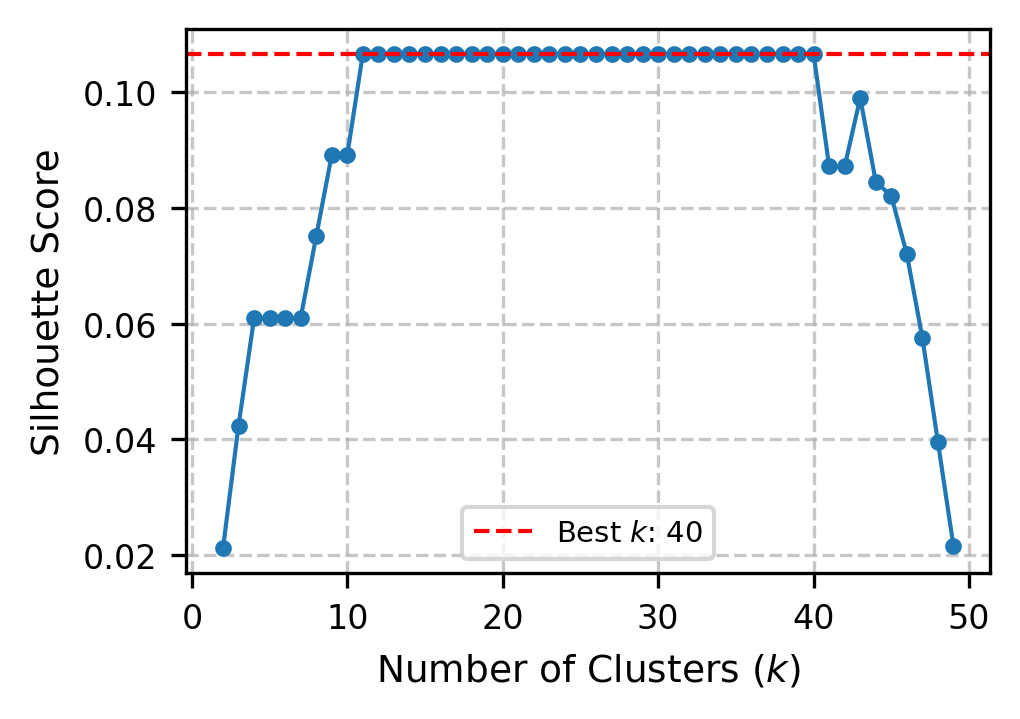

In [27]:
# --- Q1 | QUERIES ---

# Load Dataset
dataset, queries, qrels, docs = load_ir_dataset("cord19/trec-covid")
topics_data = queries

# Use the function to find best clustering
results = find_best_clustering(topics_data, min_k=2, max_k=50, distance_metric='cosine', algorithm='kmeans', max_df=5, is_query=True)

# Extract results
topics_best_k = results['best_k']
best_score = results['best_score']
best_clustering = results['best_clustering']
k_silhouette = results['k_silhouette']

# Present Results
print(f"Best k: {topics_best_k}, Best Silhouette Score: {best_score}")
plt.figure(figsize=(3.5, 2.5), dpi=300)
plt.plot([k for k, score in k_silhouette], [score for k, score in k_silhouette],
         marker='o', markersize=3, linewidth=1)
plt.xlabel('Number of Clusters ($k$)', fontsize=9)
plt.ylabel('Silhouette Score', fontsize=9)
plt.axhline(y=best_score, color='r', linestyle='--', linewidth=1,
            label=f'Best $k$: {topics_best_k}')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tick_params(axis='both', labelsize=8)
plt.legend(fontsize=7)
plt.tight_layout()
plt.show()

**(2)** Are the clusters from previous solutions cohesive? And well separated?

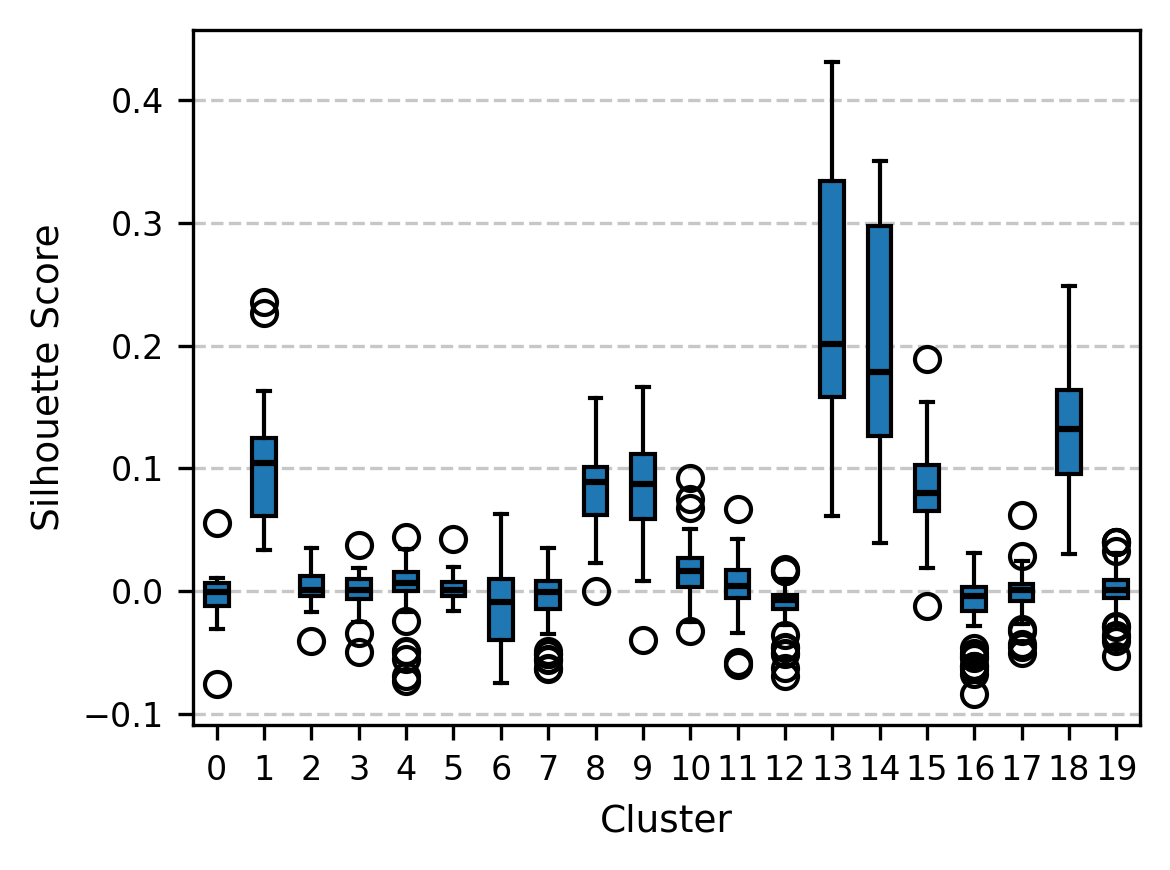

In [28]:
# --- Q2 | CORPUS ---

# Evaluate Clustering at best k
docs_evaluation_results = evaluate(docs_data, n_clusters=docs_best_k, distance_metric='cosine', algorithm='kmeans', min_df=1, max_df=1.0, is_query=False)
clustering_result = docs_evaluation_results['clustering_solution']
silhouette = docs_evaluation_results['silhouette']

# Present results
plt.figure(figsize=(4, 3), dpi=300)
data_silhouette = [silhouette[label] for label in sorted(silhouette.keys())]
plt.boxplot(data_silhouette, patch_artist=True, medianprops={'color': 'black', 'linewidth': 1.5})
plt.xlabel('Cluster', fontsize=9)
plt.ylabel('Silhouette Score', fontsize=9)
plt.xticks(range(1, len(sorted(silhouette.keys()))+1), sorted(silhouette.keys()), fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.show()

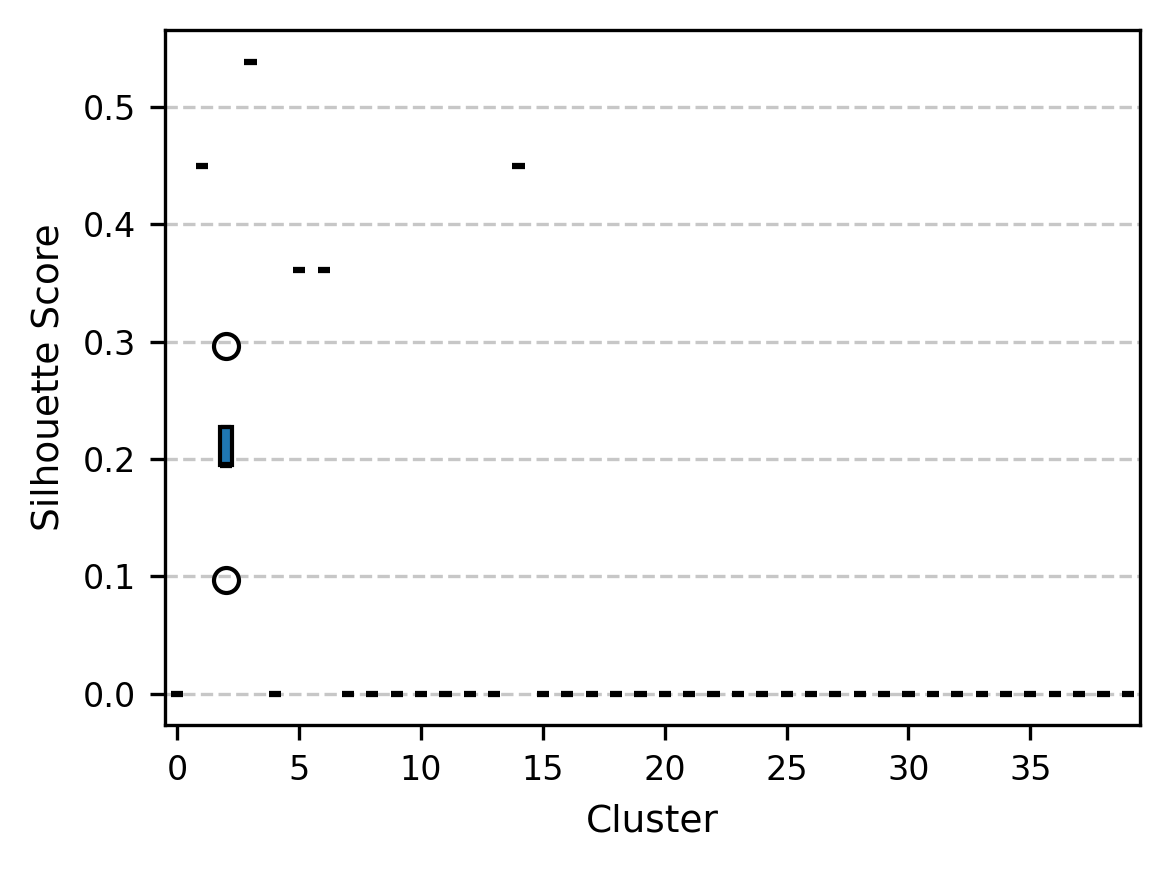

In [29]:
# --- Q2 | QUERIES ---

# Evaluate Clustering at best k
topics_evaluation_results = evaluate(topics_data, n_clusters=topics_best_k, distance_metric='cosine', algorithm='kmeans', min_df=1, max_df=5, is_query=True)
clustering_result = topics_evaluation_results['clustering_solution']
silhouette = topics_evaluation_results['silhouette']

# Present results
plt.figure(figsize=(4, 3), dpi=300)
data_silhouette = [silhouette[label] for label in sorted(silhouette.keys())]
plt.boxplot(data_silhouette, patch_artist=True, medianprops={'color': 'black', 'linewidth': 1.5})
plt.xlabel('Cluster', fontsize=9)
plt.ylabel('Silhouette Score', fontsize=9)
all_labels = sorted(silhouette.keys())
all_positions = range(1, len(all_labels)+1)
step = 5
tick_positions = all_positions[::step]
tick_labels = all_labels[::step]
plt.xticks(tick_positions, tick_labels, fontsize=8)
plt.yticks(fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7, axis='y')
plt.tight_layout()
plt.show()

**(3)** What the clustering of topic documents, Q, reveals regarding their conceptual organization and independence? Are there highly similar/overlapping topics?

In [30]:
# --- Q3 ---

# Build a mapping from query_id to query object
query_map = {query.query_id: query for query in topics_data}

# Print Clustering Solution
print("Queries in each cluster:")
for cluster_label, query_ids in clustering_result['clusters'].items():
    print(f"\nCluster {cluster_label} [{len(query_ids)}]:")
    for qid in query_ids:
        query = query_map.get(qid)
        if query:
            print(f"  {qid}: {query.title}")
        else:
            print(f"  {qid}: Query not found.")

Queries in each cluster:

Cluster 35 [1]:
  1: coronavirus origin

Cluster 6 [2]:
  2: coronavirus response to weather changes
  38: COVID inflammatory response

Cluster 3 [2]:
  3: coronavirus immunity
  49: post-infection COVID-19 immunity

Cluster 31 [1]:
  4: how do people die from the coronavirus

Cluster 7 [1]:
  5: animal models of COVID-19

Cluster 5 [2]:
  6: coronavirus test rapid testing
  7: serological tests for coronavirus

Cluster 8 [1]:
  8: coronavirus under reporting

Cluster 12 [1]:
  9: coronavirus in Canada

Cluster 2 [5]:
  10: coronavirus social distancing impact
  18: masks prevent coronavirus
  22: coronavirus heart impacts
  44: impact of masks on coronavirus transmission
  45: coronavirus mental health impact

Cluster 24 [1]:
  11: coronavirus hospital rationing

Cluster 27 [1]:
  12: coronavirus quarantine

Cluster 15 [1]:
  13: how does coronavirus spread

Cluster 29 [1]:
  14: coronavirus super spreaders

Cluster 4 [1]:
  15: coronavirus outside body

Clus

**(4)** Given a specific cluster of topics, check whether the medoid (a sort of prototype topic for the cluster) adequately represents the remaining topics in the given cluster.

In [31]:
# --- Q4 ---

# Get the clusters from clustering_result
clusters = clustering_result['clusters']

# Remove clusters that have less than two queries
threshold = 2
valid_cluster_ids = [cluster_id for cluster_id, topic_ids in clusters.items() if len(topic_ids) > threshold]

# Specify the number of random clusters to pick
n = 3
if len(valid_cluster_ids) < n:
    print(f"Only {len(valid_cluster_ids)} clusters have more than {threshold} queries. Selecting all of them.")
    n = len(valid_cluster_ids)

# Randomly sample n clusters from the valid clusters
random_clusters = random.sample(valid_cluster_ids, n)

print("\nRandomly Selected Clusters:\n")
for cluster_id in random_clusters:
    topic_ids = clusters[cluster_id]

    # Get interpretation for the cluster
    interpretation = interpret(
        cluster_items=topic_ids,
        items=topics_data,
        X=clustering_result['X'],
        item_ids=clustering_result['item_ids'],
        distance_matrix=clustering_result['distance_matrix'],
        is_query=True
    )

    print(f"Cluster {cluster_id} [size: {len(topic_ids)}]:")
    print("Queries:")
    for qid in topic_ids:
        query = query_map.get(qid)
        if query:
            print(f"  {qid}: {query.title}")
        else:
            print(f"  {qid}: Query not found.")

    print(f"Most common words: {interpretation['interpret_common_words']}")
    print(f"Cluster median (ID: {interpretation['median_id']}): {interpretation['interpret_median']}")
    print(f"Cluster medoid (ID: {interpretation['medoid_id']}): {interpretation['interpret_medoid']}")
    print("-" * 40)

Only 1 clusters have more than 2 queries. Selecting all of them.

Randomly Selected Clusters:

Cluster 2 [size: 5]:
Queries:
  10: coronavirus social distancing impact
  18: masks prevent coronavirus
  22: coronavirus heart impacts
  44: impact of masks on coronavirus transmission
  45: coronavirus mental health impact
Most common words: coronavirus impact mask social distancing prevent heart transmission mental health
Cluster median (ID: 10): coronavirus social distancing impact
Cluster medoid (ID: 44): impact mask coronavirus transmission
----------------------------------------


**(5)** How are the documents in the target collection organized? Briefly discuss the importance of this information to understand the behavior of the target IR system.

In [32]:
# --- Q5 ---

clustering_result = docs_evaluation_results['clustering_solution']
clusters = clustering_result['clusters']
centroids = clustering_result['centroids']

# Print Interpretation for all clusters
for cluster_id, doc_ids in clusters.items():
    interpretation = interpret(
        cluster_items=doc_ids,
        items=docs_data,
        X=clustering_result['X'],
        item_ids=clustering_result['item_ids'],
        distance_matrix=clustering_result['distance_matrix'],
        is_query=False
    )

    print(f"Cluster {cluster_id} [{len(doc_ids)}]:")
    print(f"Most common words: {interpretation['interpret_common_words']}")
    print(f"Cluster median (ID: {interpretation['median_id']}): {interpretation['interpret_median']}")
    print(f"Cluster medoid (ID: {interpretation['medoid_id']}): {interpretation['interpret_medoid']}")
    print()

Cluster 5 [95]:
Most common words: cell virus protein infection host 1 viral pathway response expression
Cluster median (ID: bx49tbui): insufficiency airway interferon activation defines clinical severity infant rsv infection
Cluster medoid (ID: 04xyhhmf): cell biologist study microbial pathogen

Cluster 3 [66]:
Most common words: cell virus mouse infection 1 viral induced type response antibody
Cluster median (ID: 1i36lsj2): involvement survival signaling pathway rubella virus induced apoptosis
Cluster medoid (ID: uq88w4fm): study mechanism protection acute viral encephalomyelitis delayed type hypersensitivity inducer cell clone

Cluster 19 [124]:
Most common words: disease health infectious human research study risk virus outbreak global
Cluster median (ID: hyum252p): assessing risk introduced chicken pathogen native bird gal pagos archipelago
Cluster medoid (ID: 4ko557n1): one health emerging infectious disease wildlife two decade progress

Cluster 7 [47]:
Most common words: 0 case 

<H3>Part II: Graph Ranking</H3>

**(1)** Does the graph ranking method based on document similarity aid IR?
Quantify the differences in performance against the baseline IR system, and establish hypotheses on why is that so. & **(4)** Does the inclusion of non-uniform prior probabilities yield performance improvements? Hypothesize why is that so.


Undirected PageRank Evaluation:
Took 26.1519 seconds to evaluate the IR system, 2.6152 seconds per query
Aggregated Evaluation Metrics:
P_10: 0.2000
ndcg_cut_10: 0.1507
ndcg: 0.2865
map: 0.0723


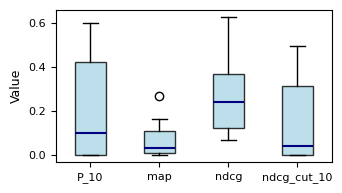


Weigthed PageRank Evaluation:
Took 24.5802 seconds to evaluate the IR system, 2.4580 seconds per query
Aggregated Evaluation Metrics:
P_10: 0.2400
ndcg_cut_10: 0.2171
ndcg: 0.3112
map: 0.0870


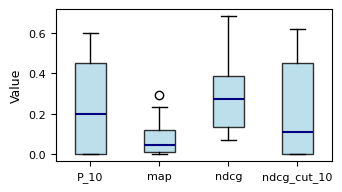


Weigthed PageRank with BM25 Evaluation:
Took 21.6568 seconds to evaluate the IR system, 2.1657 seconds per query
Aggregated Evaluation Metrics:
P_10: 0.4300
ndcg_cut_10: 0.3798
ndcg: 0.3706
map: 0.1476


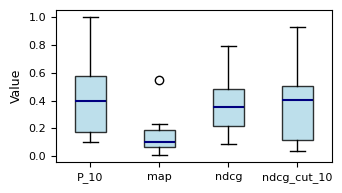

In [33]:
import matplotlib.pyplot as plt
import matplotlib as mpl

dataset, queries, qrels, docs = load_ir_dataset("cord19/trec-covid/round1")

num_graphs = 10     # For the report this was set to 30
sub_queries = queries[:num_graphs]
metrics = {'map', 'ndcg', 'P_10', 'ndcg_cut_10'}
G = build_query_graphs(index, docs, sub_queries, num_graphs=num_graphs)

############ PR ############

print("\nUndirected PageRank Evaluation:")
elapsed_time = time()
aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, 1000, ranking_method="undirected")
elapsed_time = time() - elapsed_time
print(f"Took {elapsed_time:.4f} seconds to evaluate the IR system, {elapsed_time / len(sub_queries):.4f} seconds per query")

print("Aggregated Evaluation Metrics:")
for metric, value in aggregated_metrics.items():
    print(f"{metric}: {value:.4f}")

mpl.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
})

metric_values = {metric: [] for metric in metrics}
for qid, metric_dict in per_query_results.items():
    for metric in metrics:
        metric_values[metric].append(metric_dict[metric])

ordered_metrics = sorted(metric_values.keys())
data = [metric_values[m] for m in ordered_metrics]

fig, ax = plt.subplots(figsize=(3.5, 2))
bp = ax.boxplot(data, patch_artist=True)

for box in bp['boxes']:
    box.set(facecolor='lightblue', alpha=0.8)
for median in bp['medians']:
    median.set(color='navy', linewidth=1.5)

ax.set_xticklabels(ordered_metrics)
ax.set_ylabel("Value")
fig.tight_layout()
plt.show()


############ WPR ############

print("\nWeigthed PageRank Evaluation:")
elapsed_time = time()
aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, 1000, ranking_method="weighted", alpha=1)
elapsed_time = time() - elapsed_time
print(f"Took {elapsed_time:.4f} seconds to evaluate the IR system, {elapsed_time / len(sub_queries):.4f} seconds per query")

print("Aggregated Evaluation Metrics:")
for metric, value in aggregated_metrics.items():
    print(f"{metric}: {value:.4f}")

mpl.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
})

metric_values = {metric: [] for metric in metrics}
for qid, metric_dict in per_query_results.items():
    for metric in metrics:
        metric_values[metric].append(metric_dict[metric])

ordered_metrics = sorted(metric_values.keys())
data = [metric_values[m] for m in ordered_metrics]

fig, ax = plt.subplots(figsize=(3.5, 2))
bp = ax.boxplot(data, patch_artist=True)

for box in bp['boxes']:
    box.set(facecolor='lightblue', alpha=0.8)
for median in bp['medians']:
    median.set(color='navy', linewidth=1.5)

ax.set_xticklabels(ordered_metrics)
ax.set_ylabel("Value")
fig.tight_layout()
plt.show()


############ WPR + BM25 ############

print("\nWeigthed PageRank with BM25 Evaluation:")
elapsed_time = time()
aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, 1000, ranking_method="weighted")
elapsed_time = time() - elapsed_time
print(f"Took {elapsed_time:.4f} seconds to evaluate the IR system, {elapsed_time / len(sub_queries):.4f} seconds per query")

print("Aggregated Evaluation Metrics:")
for metric, value in aggregated_metrics.items():
    print(f"{metric}: {value:.4f}")

mpl.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
})

metric_values = {metric: [] for metric in metrics}
for qid, metric_dict in per_query_results.items():
    for metric in metrics:
        metric_values[metric].append(metric_dict[metric])

ordered_metrics = sorted(metric_values.keys())
data = [metric_values[m] for m in ordered_metrics]

fig, ax = plt.subplots(figsize=(3.5, 2))
bp = ax.boxplot(data, patch_artist=True)

for box in bp['boxes']:
    box.set(facecolor='lightblue', alpha=0.8)
for median in bp['medians']:
    median.set(color='navy', linewidth=1.5)

ax.set_xticklabels(ordered_metrics)
ax.set_ylabel("Value")
fig.tight_layout()
plt.show()

**(2)** How does ranking performance vary with θ?


Results for Undirected PageRank:
Theta    MAP        nDCG       P@10       nDCG@10   
------------------------------------------------
0.1      0.0674     0.2734     0.2500     0.2025    
0.3      0.0379     0.2433     0.1500     0.0991    
0.5      0.0258     0.2308     0.1000     0.1012    
0.7      0.0180     0.2121     0.0000     0.0000    
0.9      0.0161     0.2036     0.0000     0.0000    

Results for Weighted PageRank:
Theta    MAP        nDCG       P@10       nDCG@10   
------------------------------------------------
0.1      0.0773     0.2906     0.3000     0.2638    
0.3      0.0490     0.2641     0.1500     0.1040    
0.5      0.0487     0.2678     0.1000     0.1026    
0.7      0.0617     0.2792     0.1000     0.0818    
0.9      0.0622     0.2698     0.0000     0.0000    


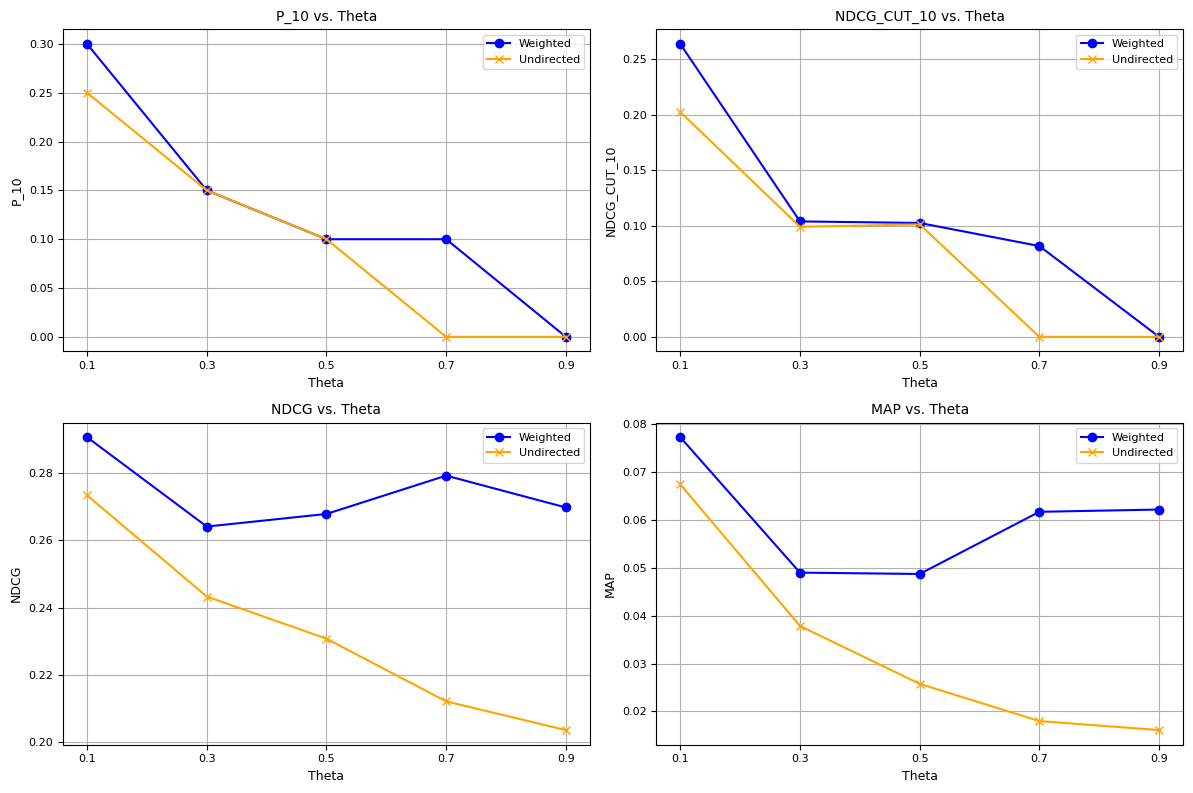

In [34]:
# WARNING: This code takes a long time to run since it requires to build 30 query graphs for each values of theta
# It might be better to reduce n_graphs, to run this code faster
n_graphs = 2        # For the report this was set to 5
sub_queries = queries[:n_graphs]
thetas = [0.1, 0.3, 0.5, 0.7, 0.9]
metrics = {'map', 'ndcg', 'P_10', 'ndcg_cut_10'}
ranking_methods = {'undirected', 'weighted'}
results = {
    'weighted': {metric: [] for metric in metrics},
    'undirected': {metric: [] for metric in metrics},
}

for t in thetas:
    G = build_query_graphs(index, docs, sub_queries, sim="cosine", theta=t, num_graphs=n_graphs)
    for ranking_function in ranking_methods:
        if ranking_function == "weighted":
            aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, num_retrieval=1000, ranking_method=ranking_function, theta=t, alpha=1)
        elif ranking_function == "undirected":
            aggregated_metrics, per_query_results = evaluation(G, sub_queries, qrels, metrics, num_retrieval=1000, ranking_method=ranking_function, theta=t)
        for metric, value in aggregated_metrics.items():
            results[ranking_function][metric].append(value)

plt.figure(figsize=(12, 8))

for ranking_method in ranking_methods:
    print(f"\nResults for {ranking_method.capitalize()} PageRank:")
    print(f"{'Theta':<8} {'MAP':<10} {'nDCG':<10} {'P@10':<10} {'nDCG@10':<10}")
    print("-" * 48)
    for i, t in enumerate(thetas):
        map_val = results[ranking_method]['map'][i]
        ndcg_val = results[ranking_method]['ndcg'][i]
        p10_val = results[ranking_method]['P_10'][i]
        ndcg10_val = results[ranking_method]['ndcg_cut_10'][i]
        print(f"{t:<8} {map_val:<10.4f} {ndcg_val:<10.4f} {p10_val:<10.4f} {ndcg10_val:<10.4f}")

for metric in metrics:
    plt.subplot(2, 2, list(metrics).index(metric) + 1)
    plt.plot(thetas, results['weighted'][metric], marker='o', label='Weighted', color='blue')
    plt.plot(thetas, results['undirected'][metric], marker='x', label='Undirected', color='orange')

    plt.title(f'{metric.upper()} vs. Theta')
    plt.xlabel('Theta')
    plt.ylabel(metric.upper())
    plt.xticks(thetas)
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()


**(3)** Upon the analysis of the graph, are there documents with higher graph centrality score? Which ones?


Results for query: 1

Top documents by Degree Centrality:
Document ID: 9sdehh8v, Score: 0.2953
Document ID: 52kqp9yw, Score: 0.2823
Document ID: 89fol3pq, Score: 0.2392
Document ID: msohf5oa, Score: 0.2322
Document ID: o47v5vgw, Score: 0.2262
Document ID: k560qnyi, Score: 0.2262
Document ID: d2knbzhl, Score: 0.2252
Document ID: 1qkwsh6a, Score: 0.2232
Document ID: o877uul1, Score: 0.2232
Document ID: sn7rswab, Score: 0.2202

Top documents by Closeness Centrality:
Document ID: 9sdehh8v, Score: 0.5227
Document ID: 52kqp9yw, Score: 0.5187
Document ID: a21ub1e9, Score: 0.5093
Document ID: 89fol3pq, Score: 0.5072
Document ID: k560qnyi, Score: 0.5034
Document ID: msohf5oa, Score: 0.4971
Document ID: sn7rswab, Score: 0.4969
Document ID: d2knbzhl, Score: 0.4935
Document ID: 1mjaycee, Score: 0.4933
Document ID: pi6a2ql7, Score: 0.4933

Top documents by Betweenness Centrality:
Document ID: 9sdehh8v, Score: 0.0292
Document ID: a21ub1e9, Score: 0.0241
Document ID: t3t20wji, Score: 0.0239
Document

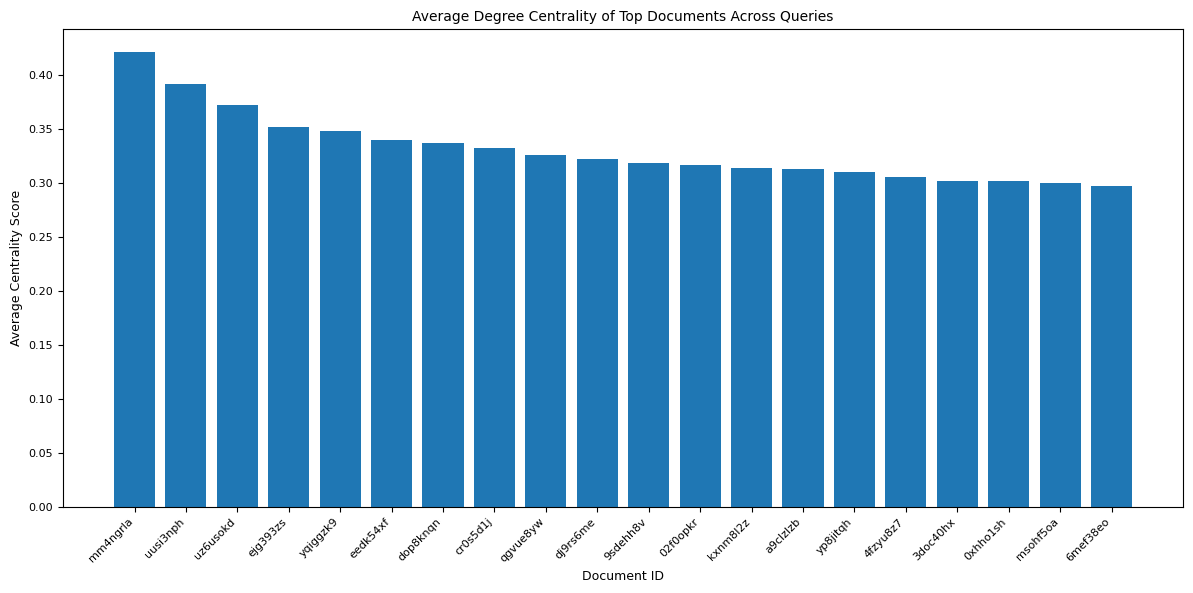

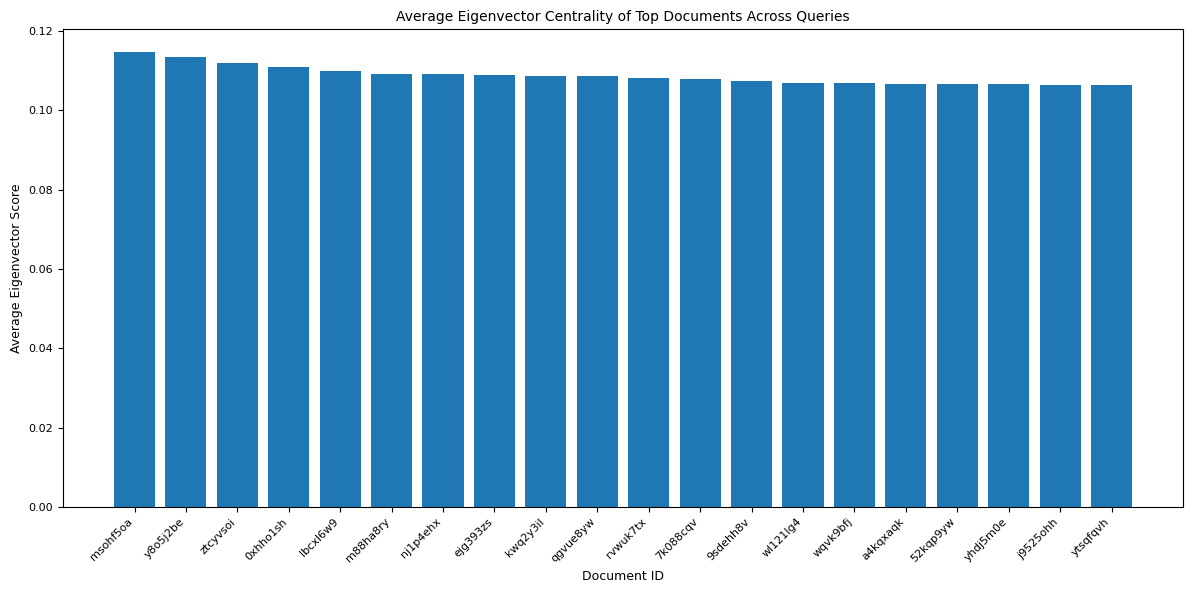

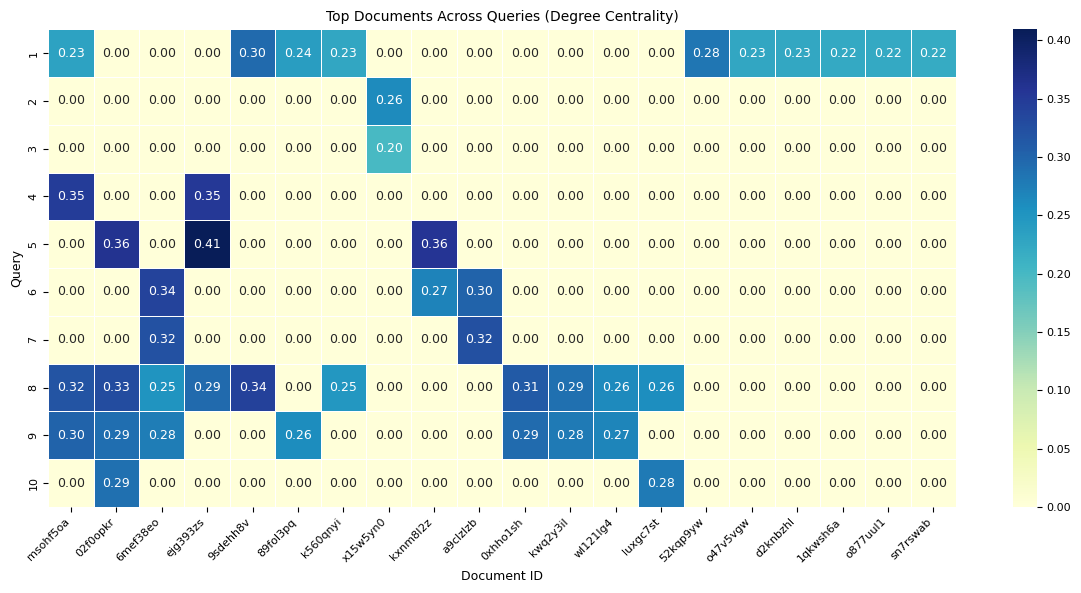

In [35]:
n_graphs = 10       # For the report this was set to 30
sub_queries = queries[:n_graphs]
G = build_query_graphs(index, docs, sub_queries, num_graphs=n_graphs)

def analyze_graph_centrality(G):
    degree_centrality = nx.degree_centrality(G)
    closeness_centrality = nx.closeness_centrality(G)
    betweenness_centrality = nx.betweenness_centrality(G)
    eigenvector_centrality = nx.eigenvector_centrality(G)

    centrality_report = {
        'degree_centrality': degree_centrality,
        'closeness_centrality': closeness_centrality,
        'betweenness_centrality': betweenness_centrality,
        'eigenvector_centrality': eigenvector_centrality,
    }

    return centrality_report

def collect_top_documents(centrality_scores, p=10):
    top_docs_results = {}
    for centrality_type, scores in centrality_scores.items():
        top_docs = sorted(scores.items(), key=lambda item: item[1], reverse=True)[:p]
        top_docs_results[centrality_type] = top_docs

    return top_docs_results

def print_query_results(all_query_results):
    for query_id, results in all_query_results.items():
        print(f"\nResults for query: {query_id}")
        for centrality_type, top_docs in results.items():
            print(f"\nTop documents by {centrality_type.replace('_', ' ').title()}:")
            for doc_id, score in top_docs:
                print(f"Document ID: {doc_id}, Score: {score:.4f}")


all_query_results = {}
for query in sub_queries:
    centrality_scores = analyze_graph_centrality(G[query.query_id][0])
    all_query_results[query.query_id] = collect_top_documents(centrality_scores, p=10)
print_query_results(all_query_results)


# Average Centrality Scores

def average_centrality_scores(all_query_results, centrality_type):
    doc_scores = defaultdict(list)

    for query_results in all_query_results.values():
        for doc_id, score in query_results[centrality_type]:
            doc_scores[doc_id].append(score)

    averaged_scores = {doc_id: np.mean(scores) for doc_id, scores in doc_scores.items()}

    return averaged_scores

averaged = average_centrality_scores(all_query_results, centrality_type="degree_centrality")
top_docs = dict(sorted(averaged.items(), key=lambda x: x[1], reverse=True)[:20])

plt.figure(figsize=(12, 6))
plt.bar(list(top_docs.keys()), list(top_docs.values()))
plt.xticks(rotation=45, ha='right')
plt.title("Average Degree Centrality of Top Documents Across Queries")
plt.xlabel("Document ID")
plt.ylabel("Average Centrality Score")
plt.tight_layout()
plt.show()

averaged = average_centrality_scores(all_query_results, centrality_type="eigenvector_centrality")
top_docs = dict(sorted(averaged.items(), key=lambda x: x[1], reverse=True)[:20])

plt.figure(figsize=(12, 6))
plt.bar(list(top_docs.keys()), list(top_docs.values()))
plt.xticks(rotation=45, ha='right')
plt.title("Average Eigenvector Centrality of Top Documents Across Queries")
plt.xlabel("Document ID")
plt.ylabel("Average Eigenvector Score")
plt.tight_layout()
plt.show()

# Heatmap of docs centrality score across all queries

def get_top_doc_frequencies(all_query_results, centrality_type='degree_centrality', top_k=10):
    # Count how many times each doc appears in top-k results across all queries
    doc_counter = Counter()
    for query_results in all_query_results.values():
        top_docs = query_results.get(centrality_type, [])
        doc_counter.update([doc_id for doc_id, _ in top_docs])

    return doc_counter

def plot_summary_heatmap(all_query_results, centrality_type='degree_centrality', top_k=10):
    # Get frequency of docs in top results
    doc_counter = get_top_doc_frequencies(all_query_results, centrality_type, top_k)
    most_common_docs = doc_counter.most_common(20)  # change 20 to any number you like

    # Create DataFrame: rows are queries, columns are doc IDs
    doc_ids = [doc_id for doc_id, _ in most_common_docs]
    query_titles = list(all_query_results.keys())

    data = []
    for query in query_titles:
        row = []
        top_docs = dict(all_query_results[query].get(centrality_type, []))
        for doc_id in doc_ids:
            row.append(top_docs.get(doc_id, 0))  # 0 if not in top-k
        data.append(row)

    df = pd.DataFrame(data, index=query_titles, columns=doc_ids)

    # Plot
    plt.figure(figsize=(12, len(query_titles) * 0.4 + 2))
    sns.heatmap(df, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5)
    plt.title(f"Top Documents Across Queries ({centrality_type.replace('_', ' ').title()})")
    plt.xlabel("Document ID")
    plt.ylabel("Query")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

plot_summary_heatmap(all_query_results, centrality_type='degree_centrality')

<H3>END</H3>